# code_038 · Joins, keys and relational structure

**Book:** section 8.2. A dataset-construction laboratory using invented structural-monitoring records. Prerequisites: Python arrays, tables and Chapter 7's information boundaries. Restart and run all cells. Every import, helper and input is here; no ordinary-run files, network, credentials, GPU or private helper are required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_08_GUIDE.md), [run evidence](../CHAPTER_08_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_038).

Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0, CPU. Allow one minute to execute and 30–60 minutes to interpret. These are scoped data-contract experiments rather than exhaustive estimator API studies. Construction identities have no training/test interpretation. The sampling laboratory alone fits two fixed constant predictors and protects an independent final population. No engineering reliability or causal maintenance conclusion follows.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=838;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 838


<a id="relations"></a>
## Source relations and the learning unit

Four buildings contain three members each. Each member has zero to three sensors and one to four historical inspections; sensors have two readings. All records precede the hypothetical prediction cutoff, so this lab isolates cardinality rather than timing. Length 2–13 m is a member attribute. The learning view must have one row per member, including member 11 with no sensor. IDs are global in this generator; local source IDs would require building/member composite keys. A foreign key must resolve, and a primary key must be unique and non-null.

Predict before running: joining readings and inspections through a member creates a Cartesian product within that member. Counting joined rows counts combinations, not inspections or members. No predictor is fitted; this is an executable construction invariant.


In [2]:
buildings=pd.DataFrame({'building_id':np.arange(4),'age_years':[10,25,40,55]})
members=pd.DataFrame({'member_id':np.arange(12),'building_id':np.repeat(np.arange(4),3),'length_m':np.arange(2.,14.)})
sensors=pd.DataFrame([(f's{m}_{j}',m) for m in range(12) for j in range(0 if m==11 else 1+m%3)],columns=['sensor_id','member_id'])
readings=pd.DataFrame([(s,k,.1*m+.01*k) for s,m in sensors.itertuples(index=False,name=None) for k in [0,1]],columns=['sensor_id','time_index','value_mm'])
inspections=pd.DataFrame([(f'i{m}_{j}',m,j%2) for m in range(12) for j in range(1+m%4)],columns=['inspection_id','member_id','finding'])
for frame,key in [(buildings,'building_id'),(members,'member_id'),(sensors,'sensor_id'),(inspections,'inspection_id')]:
 assert frame[key].notna().all() and frame[key].is_unique
assert not readings.duplicated(['sensor_id','time_index']).any()
assert set(members.building_id)<=set(buildings.building_id) and set(sensors.member_id)<=set(members.member_id)
assert set(inspections.member_id)<=set(members.member_id) and set(readings.sensor_id)<=set(sensors.sensor_id)
# An explicit invalid foreign-key fixture must fail the subset invariant.
assert not set([999])<=set(members.member_id)
RESULTS['source_counts']={'buildings':len(buildings),'members':len(members),'sensors':len(sensors),'readings':len(readings),'inspections':len(inspections)}


<a id="amplification"></a>
## Catch a many-to-many expansion

The unsafe inner view repeats every sensor reading once per inspection and drops members without sensors. Pandas validate='many_to_many' allows this; it is not a uniqueness check. A deliberate many-to-one request should reject the inspection table's repeated member key. A left join would retain missing members but still multiply rows, so changing join type alone is insufficient.


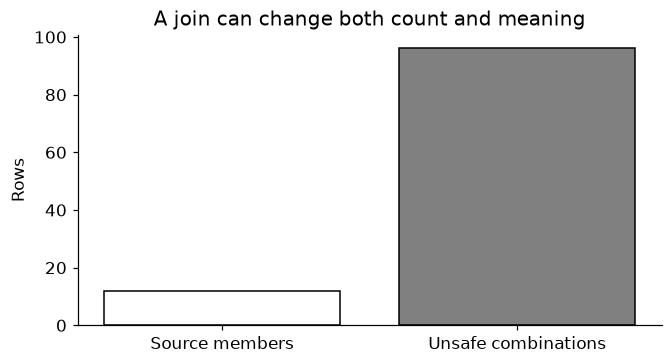

In [3]:
reading_members=readings.merge(sensors,on='sensor_id',validate='many_to_one')
unsafe=members.merge(reading_members,on='member_id',validate='one_to_many').merge(inspections,on='member_id',validate='many_to_many')
rejected=False
try:members.merge(inspections,on='member_id',validate='many_to_one')
except pd.errors.MergeError:rejected=True
assert rejected
r=reading_members.groupby('member_id').size().reindex(members.member_id,fill_value=0).to_numpy();j=inspections.groupby('member_id').size().reindex(members.member_id).to_numpy()
assert len(unsafe)==int((r*j).sum()) and 11 not in set(unsafe.member_id)
unsafe_mean=float(unsafe.length_m.mean());member_mean=float(members.length_m.mean())
assert not np.isclose(unsafe_mean,member_mean)
fig,ax=plt.subplots(figsize=(6,3.2));ax.bar(['Source members','Unsafe combinations'],[len(members),len(unsafe)],color=['white','.5'],edgecolor='black');ax.set(ylabel='Rows',title='A join can change both count and meaning');plt.show()
RESULTS.update({'unsafe_rows':len(unsafe),'equal_member_mean_length_m':member_mean,'unsafe_row_mean_length_m':unsafe_mean,'dropped_member_ids':[11],'cardinality_error_caught':rejected})


<a id="repair"></a>
## Aggregate separately, then join at member level

Compute sensor-reading mean and distinct inspection count separately before joining. The mean weights readings equally; it would differ from equally weighting sensors with unequal sampling rates. Retain both reading and sensor counts so that choice is inspectable. Finding counts are historical summaries, not future labels; using future inspections would violate a different boundary. Preserve original relations because the mean erases event order and sensor identity.


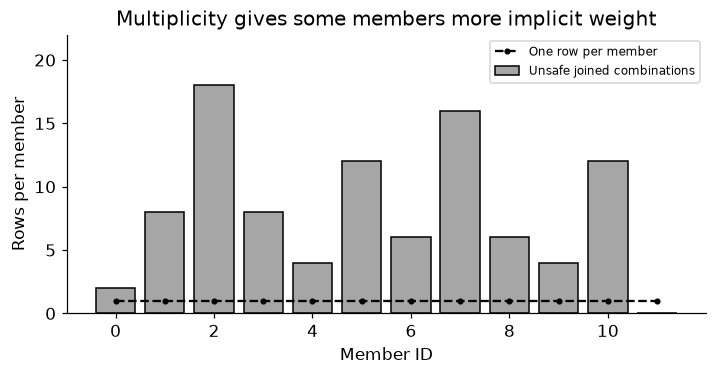

,member_id,building_id,length_m,age_years,sensor_mean_mm,reading_count,sensor_count,inspection_count
0,0,0,2.0,10,0.005,2.0,1.0,1
1,1,0,3.0,10,0.105,4.0,2.0,2
2,2,0,4.0,10,0.205,6.0,3.0,3
3,3,1,5.0,25,0.305,2.0,1.0,4
4,4,1,6.0,25,0.405,4.0,2.0,1
5,5,1,7.0,25,0.505,6.0,3.0,2
6,6,2,8.0,40,0.605,2.0,1.0,3
7,7,2,9.0,40,0.705,4.0,2.0,4
8,8,2,10.0,40,0.805,6.0,3.0,1
9,9,3,11.0,55,0.905,2.0,1.0,2


In [4]:
a=reading_members.groupby('member_id').agg(sensor_mean_mm=('value_mm','mean'),reading_count=('value_mm','size'),sensor_count=('sensor_id','nunique')).reset_index()
b=inspections.groupby('member_id').agg(inspection_count=('inspection_id','nunique')).reset_index()
view=members.merge(buildings,on='building_id',validate='many_to_one').merge(a,on='member_id',how='left',validate='one_to_one').merge(b,on='member_id',how='left',validate='one_to_one')
assert len(view)==12 and view.member_id.is_unique and set(view.member_id)==set(members.member_id)
assert view.loc[view.member_id==11,'sensor_mean_mm'].isna().all()
assert int(view.inspection_count.sum())==len(inspections)
assert int(view.reading_count.fillna(0).sum())==len(readings)
assert np.isclose(view.length_m.mean(),member_mean)
fig,ax=plt.subplots(figsize=(6.4,3.3));ax.bar(members.member_id,r*j,color='.65',edgecolor='black',label='Unsafe joined combinations');ax.plot(members.member_id,np.ones(12),'ko--',ms=3,label='One row per member');ax.set(xlabel='Member ID',ylabel='Rows per member',ylim=(0,22),title='Multiplicity gives some members more implicit weight');ax.legend(fontsize=8);plt.show()
RESULTS['repaired_rows']=len(view);RESULTS['rows_per_member_unsafe']=(r*j).tolist();display(view)


<a id="exercises"></a>
## Exercises, hints and troubleshooting

1. Give two buildings the same local member number. Repair with a composite key before joining.
2. Add a sensor with one hundred readings. Compare reading-weighted and sensor-weighted averages.
3. Add a null member key. Reject it before joining: pandas may match null keys to each other, unlike usual SQL semantics.
4. Specify a graph edge list preserving the membership relation that this flat view discards.

**Hints:** validate keys at ingestion, measure distinct entities before and after joins, and define aggregation weights. Rejecting a many-to-many view is appropriate only when that view violates the stated learning unit. Official [merge documentation](https://pandas.pydata.org/docs/reference/api/pandas.merge.html) describes cardinality and null-key semantics; the executed version is pandas 3.0.3 and live docs may advance.


In [5]:
summary={'example_id':'code_038','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['primary foreign and composite keys', 'join multiplicity and duplicate amplification', 'aggregation at the declared learning unit', 'missing-related-record preservation', 'flattened views retain source lineage'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["primary foreign and composite keys", "join multiplicity and duplicate amplification", "aggregation at the declared learning unit", "missing-related-record preservation", "flattened views retain source lineage"], "elapsed_seconds": 0.108, "example_id": "code_038", "hardware": "Darwin arm64 CPU", "results": {"cardinality_error_caught": true, "dropped_member_ids": [11], "equal_member_mean_length_m": 7.5, "repaired_rows": 12, "rows_per_member_unsafe": [2, 8, 18, 8, 4, 12, 6, 16, 6, 4, 12, 0], "source_counts": {"buildings": 4, "inspections": 30, "members": 12, "readings": 42, "sensors": 21}, "unsafe_row_mean_length_m": 7.166666666666667, "unsafe_rows": 96}, "seed": 838, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
